In [1]:
%load_ext autoreload
%autoreload 1

In [2]:
import networkx as nx

from actors_graph import ActorsGraph

actors_graph = ActorsGraph("../resources/movie/data/casts.html")
actors_graph.build()
nx.write_gexf(actors_graph.g, "../results/actor_graph.gexf")

In [4]:
stats = actors_graph.stats()
print(stats)

{'nodes_count': 15848, 'edges_count': 143972, 'density': 0.0011465328776337916, 'clustering_coefficient': 0.7172466780239253, 'bridges': [('ray milland', 'claire griswold'), ('sophia loren', 'luca defillipo'), ('richard boone', 'joan vanark'), ('harvey keitel', 'zina bethune'), ('marcello mastroianni', 'anouk grinberg'), ('michael riley', 'stephen rappaport'), ('albert brooks', 'super dave osborne'), ('charles grodin', 'marlo thomas'), ('rip torn', 'kevin conway'), ('seymour hicks', 'ellaline teriss'), ('richard roundtree', 'ed kovens'), ('duke howard', 'burt brinckerhoff'), ('marshall thompson', 'marla landi'), ('ethan hawke', 'julie delpie'), ('robert deniro', 'lenny bruce'), ('emilio estevez', 'phil brock'), ('anouk aimee', 'ives montand'), ('claude noiller', 'valentine tessier'), ('jean gabin', 'josephine baker'), ('lyda bonelli', 'mario bonnard'), ('christopher dienstag', 'monica caldwell'), ('kim basinger', 'lisa croisette'), ('michael douglas', 'marjorie griffiths'), ('glenn clo

## Bridges with degree higher than one 1

In [29]:
print("Bridges count: ", len(stats["bridges"]))
bridges = [
    (a, b) for (a, b) in stats["bridges"]
    if actors_graph.g.degree(a) > 1 and actors_graph.g.degree(b) > 1
]
bridges

Bridges count:  438


[('giacomo rossistuart', 'vincent price'),
 ('karen black', 'michael emil'),
 ('chuck connors', 'rosel zech'),
 ('john hargreaves', 'bryan brown'),
 ('helmut berger', 'marisa mell'),
 ('john belushi', 'blair brown'),
 ('francisco rabal', 'silvia pinal')]

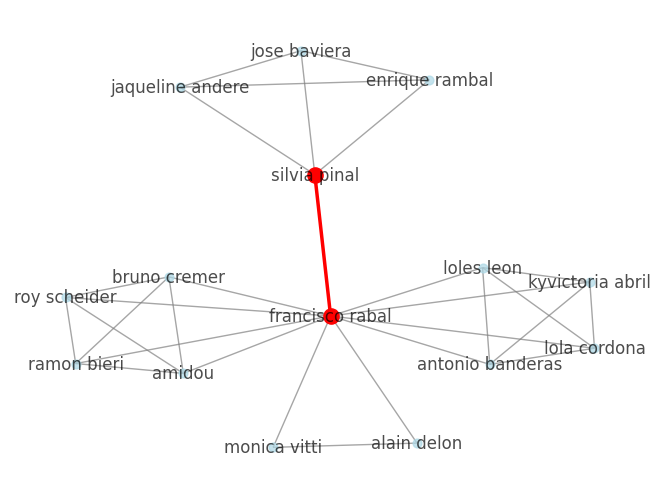

In [28]:
import networkx as nx
from matplotlib import pyplot as plt

u, v = ('francisco rabal', 'silvia pinal')
# nodes_u = nx.single_source_shortest_path_length(actors_graph.g, u, cutoff=2).keys()
nodes_u = nx.neighbors(actors_graph.g, u)
nodes_v = nx.neighbors(actors_graph.g, v)
# nodes_v = nx.single_source_shortest_path_length(actors_graph.g, v, cutoff=2).keys()
nodes = set(nodes_u) | set(nodes_v)

subG = actors_graph.g.subgraph(nodes).copy()
pos = nx.kamada_kawai_layout(subG)
scale = 3
pos = {k: (x * scale, y * scale) for k, (x, y) in pos.items()}

# base graph
nx.draw(
    subG,
    pos,
    node_size=40,
    node_color="lightblue",
    edge_color="gray",
    with_labels=True,
    alpha=0.7
)

# highlight nodes
nx.draw_networkx_nodes(
    subG,
    pos,
    nodelist=[u, v],
    node_color="red",
    node_size=120
)

# highlight edge
nx.draw_networkx_edges(
    subG,
    pos,
    edgelist=[(u, v)],
    edge_color="red",
    width=2.5
)
plt.show()

## Local bridges with degree > 1

In [ ]:
bridges = [
    (a, b) for (a, b, _) in stats["local_bridges"]
    if actors_graph.g.degree(a) > 1 and actors_graph.g.degree(b) > 1
]
bridges

In [ ]:
import networkx as nx
from matplotlib import pyplot as plt

u, v = ('alfie bass', 'david kosoff')
# nodes_u = nx.single_source_shortest_path_length(actors_graph.g, u, cutoff=2).keys()
nodes_u = nx.neighbors(actors_graph.g, u)
nodes_v = nx.neighbors(actors_graph.g, v)
# nodes_v = nx.single_source_shortest_path_length(actors_graph.g, v, cutoff=2).keys()
nodes = set(nodes_u) | set(nodes_v)

subG = actors_graph.g.subgraph(nodes).copy()
pos = nx.kamada_kawai_layout(subG)
scale = 3  # try 2–5
pos = {k: (x * scale, y * scale) for k, (x, y) in pos.items()}

# base graph
nx.draw(
    subG,
    pos,
    node_size=40,
    node_color="lightblue",
    edge_color="gray",
    with_labels=True,
    alpha=0.7
)

# highlight nodes
nx.draw_networkx_nodes(
    subG,
    pos,
    nodelist=[u, v],
    node_color="red",
    node_size=120
)

# highlight edge
nx.draw_networkx_edges(
    subG,
    pos,
    edgelist=[(u, v)],
    edge_color="red",
    width=2.5
)
plt.show()

## Degree distribution

Top 5 by degree: [('humphrey bogart', 412), ('gary cooper', 358), ('james stewart', 357), ('john gielgud', 356), ('john carradine', 354)]
0 413 1


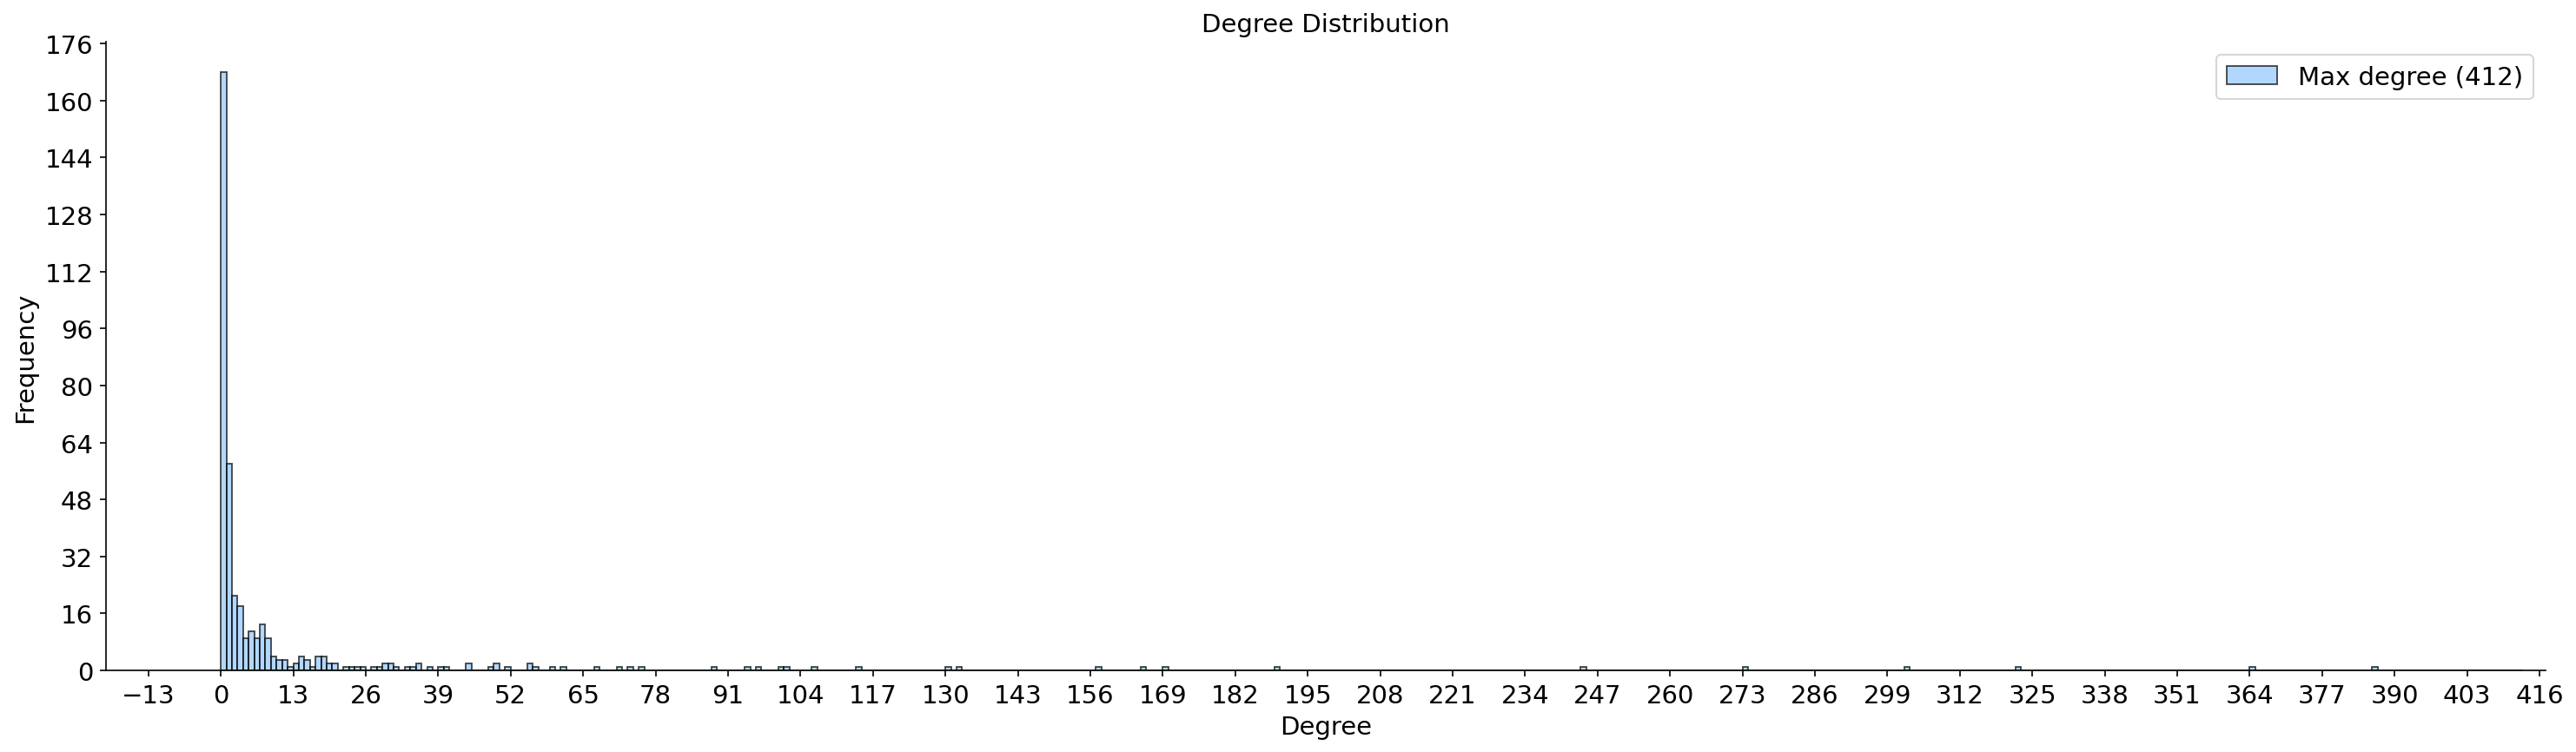

In [26]:
import importlib
import plotter
import pandas as pd

importlib.reload(plotter)

from plotter import Plotter
top_by_degree = sorted(actors_graph.g.degree, key=lambda x: x[1], reverse=True)[:5]
print("Top 5 by degree:", top_by_degree)
Plotter().plot_histogram_bin_count(
    sequence=stats["degree_histogram"],
    bins_count=len(stats["degree_histogram"]),
    log_y_scale=False,
    title="Degree Distribution",
    x_label="Degree",
    y_label="Frequency",
    label=f"Max degree ({top_by_degree[0][1]})",
    x_majors=30
)

## Components

In [5]:
components_stats = actors_graph.component_stats()

In [6]:
components_stats

{'num_components': 731,
 'largest_size': 14062,
 'largest_ratio': 0.8873043917213529,
 'singletons': 322,
 'below_10_nodes': 400,
 'below_100_nodes': 8,
 'above_100_nodes': 0}

In [7]:
components = nx.connected_components(actors_graph.g)

In [8]:
singletons = [
    comp for comp in components if len(comp) == 1
]

In [9]:
singletons[0]

{'thais galizky'}

## Centralities

In [65]:
degree_output = nx.degree_centrality(actors_graph.g)
top_by_degree = sorted(degree_output.items(), key=lambda item: item[1], reverse=True)[:10]
top_by_degree

[('humphrey bogart', 0.02599861172461665),
 ('gary cooper', 0.022591026692749417),
 ('james stewart', 0.022527923266233357),
 ('john gielgud', 0.022464819839717296),
 ('john carradine', 0.02233861298668518),
 ('peter lorre', 0.0218337855745567),
 ('c.aubrey smith', 0.020571717044235504),
 ('henry fonda', 0.019688269073010665),
 ('burt lancaster', 0.019057234807850067),
 ('david niven', 0.018931027954817947)]

In [48]:
closeness_output = nx.closeness_centrality(actors_graph.g)
top_by_closeness = sorted(closeness_output.items(), key=lambda item: item[1], reverse=True)[:10]
top_by_closeness

[('charlton heston', 0.3444204686806322),
 ('john gielgud', 0.3437277752290057),
 ('burt lancaster', 0.3431038983991206),
 ('henry fonda', 0.34006451857520775),
 ('john carradine', 0.33975891335985464),
 ('david niven', 0.3383675162043616),
 ('james stewart', 0.3374158118100179),
 ('robert mitchum', 0.33645129867556284),
 ('robert deniro', 0.33513181093497424),
 ('laurence olivier', 0.33512280903293723)]

In [83]:
for id, score in top_by_degree:
    print(id, score, actors_graph.g.degree[id])

c.aubrey smith 0.10485028886498275 326
john carradine 0.09881481860018791 354
peter lorre 0.09295870749885816 346
james stewart 0.09258502168958771 357
john gielgud 0.09131177574071166 356
gary cooper 0.09023493963125748 358
david niven 0.08839774672650973 300
basil rathbone 0.08822845125407812 293
andy devine 0.08588618791107584 243
henry fonda 0.08437356735112676 312


In [61]:
betweenness_output = nx.betweenness_centrality(actors_graph.g)
top_by_betweenness = sorted(betweenness_output.items(), key=lambda item: item[1], reverse=True)[:10]
top_by_betweenness

[('robert deniro', 0.011315137095846394),
 ('john carradine', 0.01086691513863796),
 ('vincent price', 0.010764103931666874),
 ('humphrey bogart', 0.010686893357448995),
 ('burt lancaster', 0.01057764571087529),
 ('gene hackman', 0.009937017131140062),
 ('john gielgud', 0.009453148331635056),
 ('charlton heston', 0.009323707105524007),
 ('jack nicholson', 0.00887439303377209),
 ('james stewart', 0.008032388751603566)]

In [63]:
eigenvector_output = nx.eigenvector_centrality(actors_graph.g)
top_by_eigenvector = sorted(eigenvector_output.items(), key=lambda item: item[1], reverse=True)[:10]
top_by_eigenvector


[('c.aubrey smith', 0.10485028886498275),
 ('john carradine', 0.09881481860018791),
 ('peter lorre', 0.09295870749885816),
 ('james stewart', 0.09258502168958771),
 ('john gielgud', 0.09131177574071166),
 ('gary cooper', 0.09023493963125748),
 ('david niven', 0.08839774672650973),
 ('basil rathbone', 0.08822845125407812),
 ('andy devine', 0.08588618791107584),
 ('henry fonda', 0.08437356735112676)]

In [84]:
for id, score in top_by_eigenvector:
    print(id, score, actors_graph.g.degree[id])

c.aubrey smith 0.10485028886498275 326
john carradine 0.09881481860018791 354
peter lorre 0.09295870749885816 346
james stewart 0.09258502168958771 357
john gielgud 0.09131177574071166 356
gary cooper 0.09023493963125748 358
david niven 0.08839774672650973 300
basil rathbone 0.08822845125407812 293
andy devine 0.08588618791107584 243
henry fonda 0.08437356735112676 312


In [75]:
tops = [top_by_degree, top_by_betweenness, top_by_closeness, top_by_eigenvector]
top_ids = []
for top in tops:
    top_ids.append(
        set([entry[0] for entry in top])
    )

top_intersection = top_ids[0]
for top in top_ids[1:]:
    top_intersection = top_intersection & top
top_intersection

{'james stewart', 'john carradine', 'john gielgud'}

In [76]:
top_ids[1] & top_ids[2]

{'burt lancaster',
 'charlton heston',
 'james stewart',
 'john carradine',
 'john gielgud',
 'robert deniro'}

## Clusters/Communities

In [22]:
communities = nx.community.louvain_communities(actors_graph.g)

print("Communities present", len(communities))

Communities present 782


In [23]:
print("Singleton communities", len([comm for comm in communities if len(comm) == 1]))
print("Above 10 nodes", len([comm for comm in communities if len(comm) > 10]))
print("Above 100, below 1000 nodes", len([comm for comm in communities if len(comm) > 100 and len(comm) <1000]))
print("Above 1000 nodes", len([comm for comm in communities if len(comm) > 1000]))

Singleton communities 322
Above 10 nodes 40
Above 100, below 1000 nodes 16
Above 1000 nodes 4


In [28]:
middle_size_comms = [comm for comm in communities if len(comm) > 10 and len(comm) <= 100]
# [len(comm) for comm in middle_size_comms]
comm_size_95 = middle_size_comms[-2]
print("Size of chosen community is", len(comm_size_95))

Size of chosen community is  95


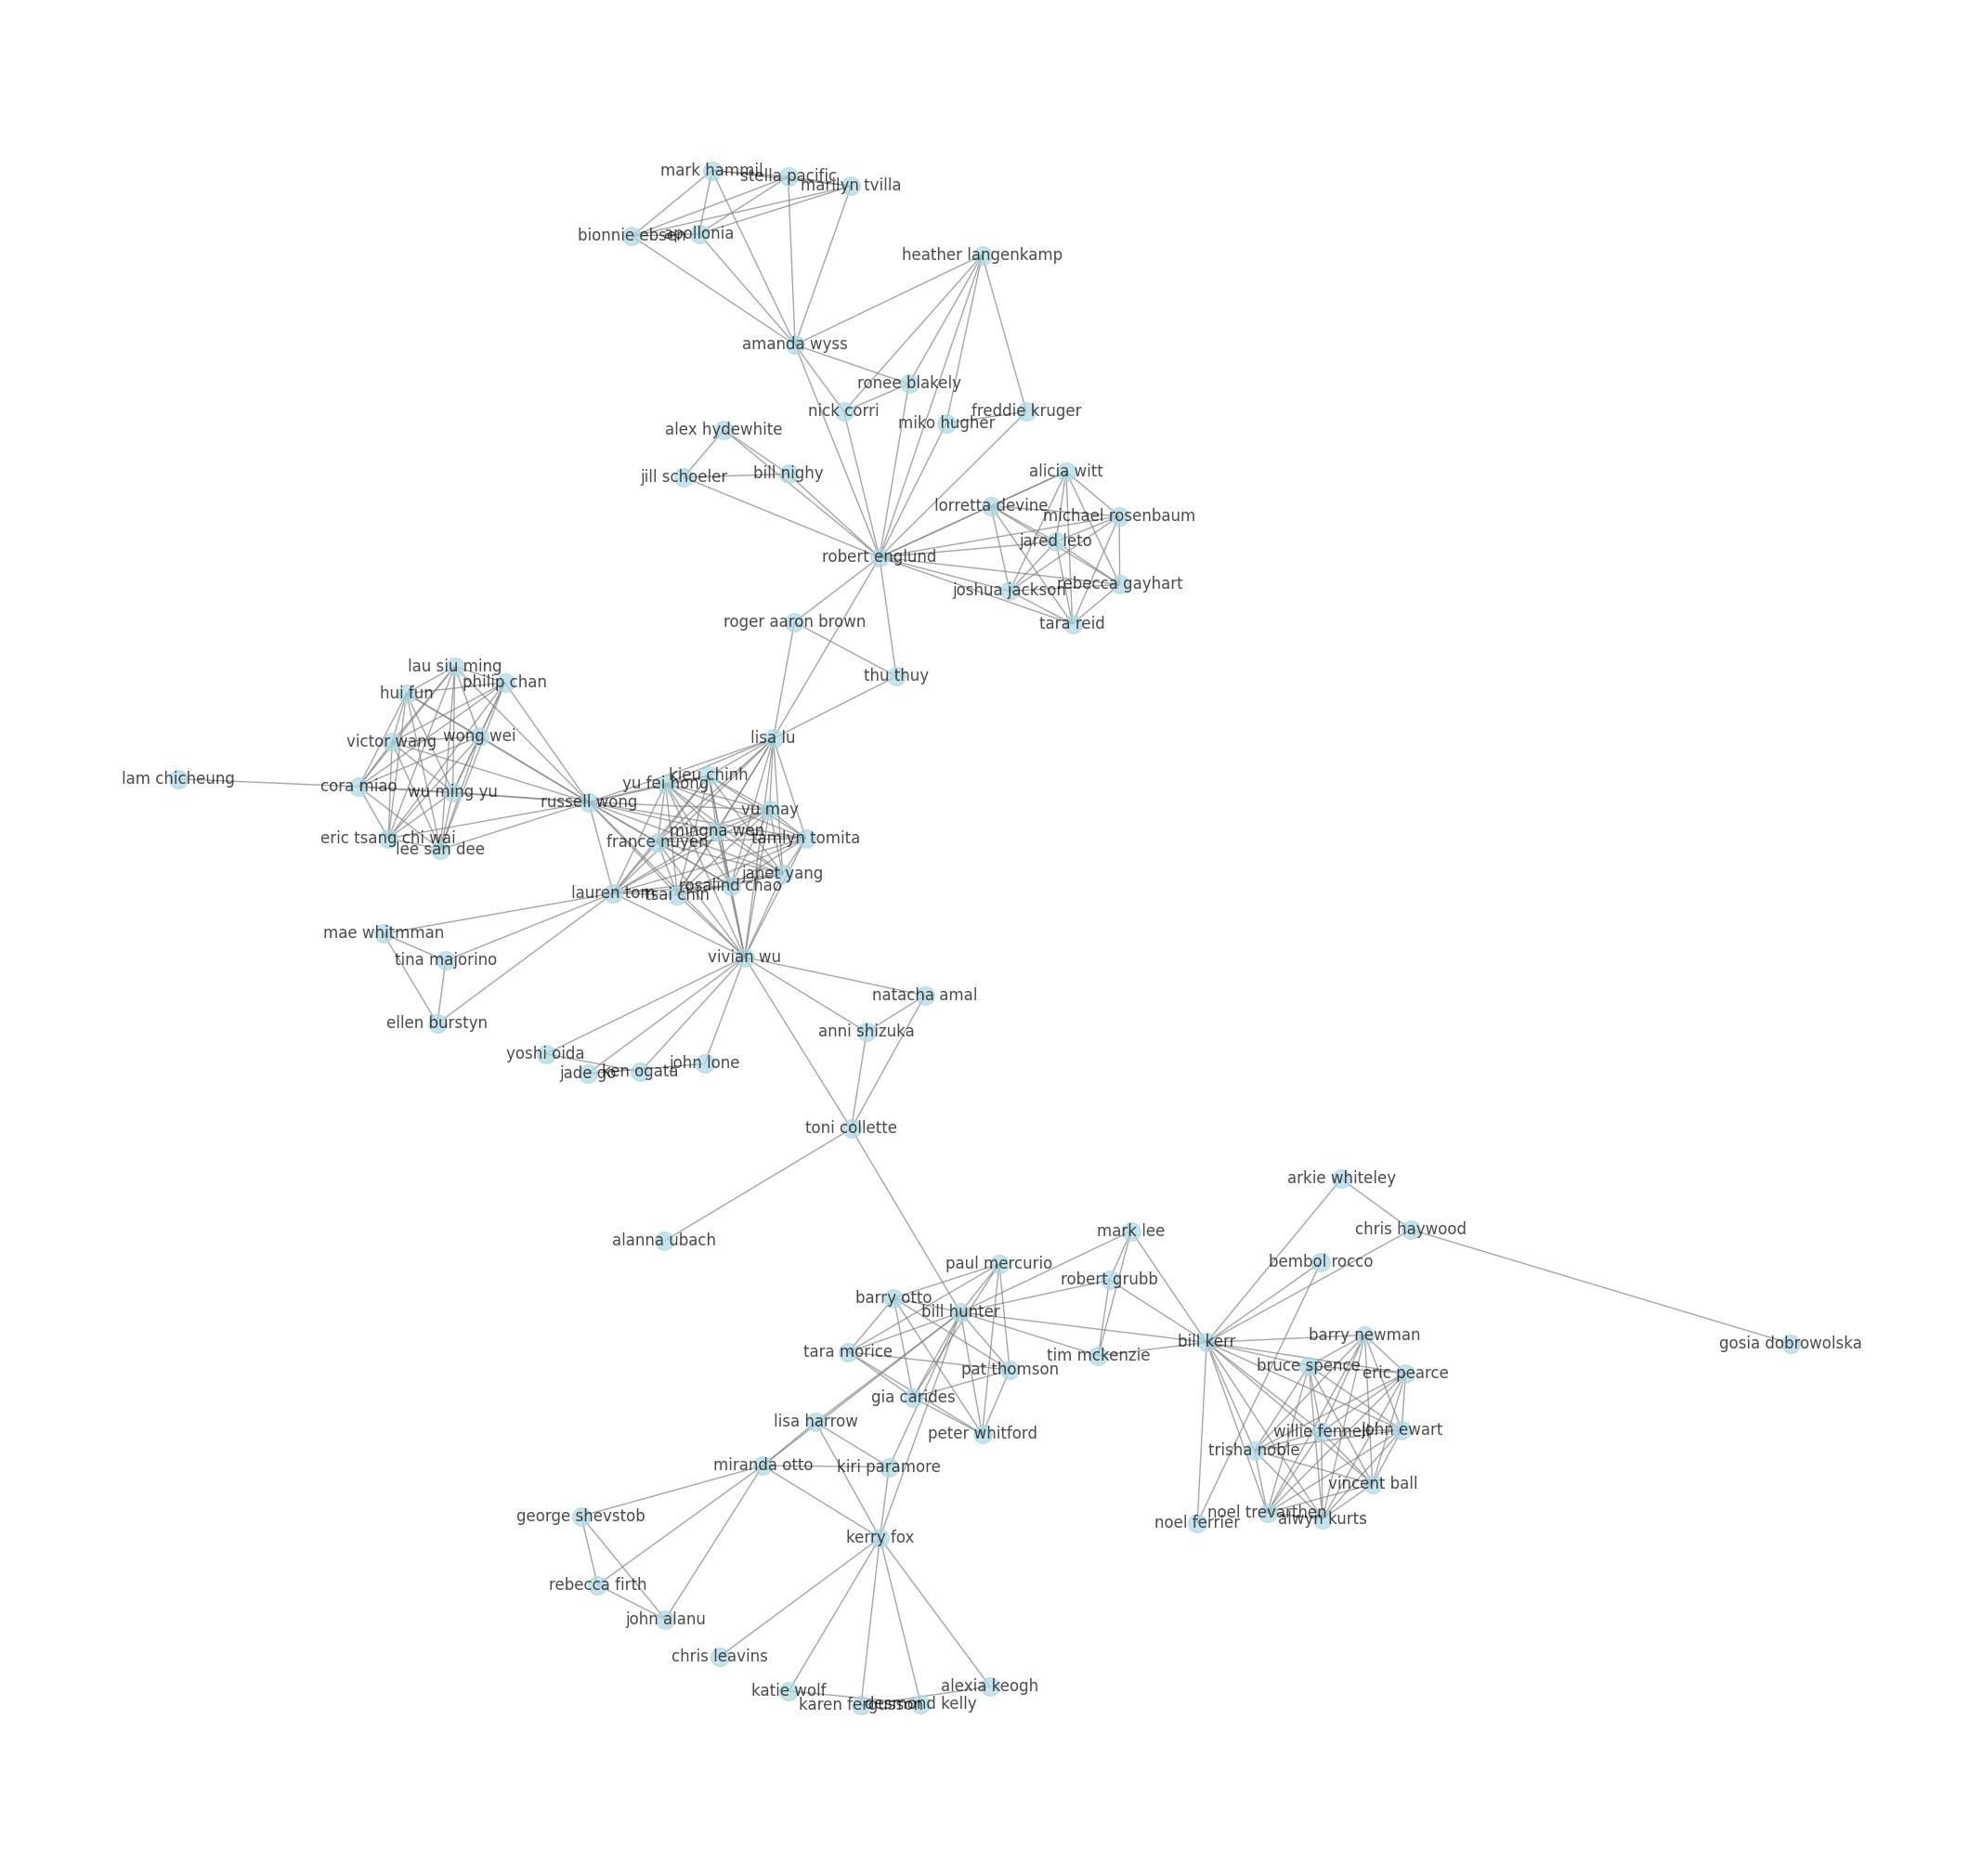

In [38]:
subgraph_g = nx.subgraph(actors_graph.g, comm_size_95)
pos = nx.kamada_kawai_layout(subgraph_g)
scale = 2
pos = {k: (x * scale, y * scale) for k, (x, y) in pos.items()}
plt.figure(1, figsize=(20, 20))
nx.draw(
    subgraph_g,
    pos,
    node_size=200,
    node_color="lightblue",
    edge_color="gray",
    with_labels=True,
    alpha=0.7
)

plt.show()

## Kevin Bacon number

In [4]:
from numpy import inf

node_distances = []
for node in actors_graph.g.nodes:
    try:
        dist = nx.shortest_path_length(actors_graph.g, source=node, target="kevin bacon")
    except:
        dist = inf
    node_distances.append({
        "node": node,
        "distance": dist
    })

In [12]:
import numpy as np
import pandas as pd
df = pd.DataFrame(node_distances, columns=["node", "distance"])
df = df[df["distance"] != np.inf]

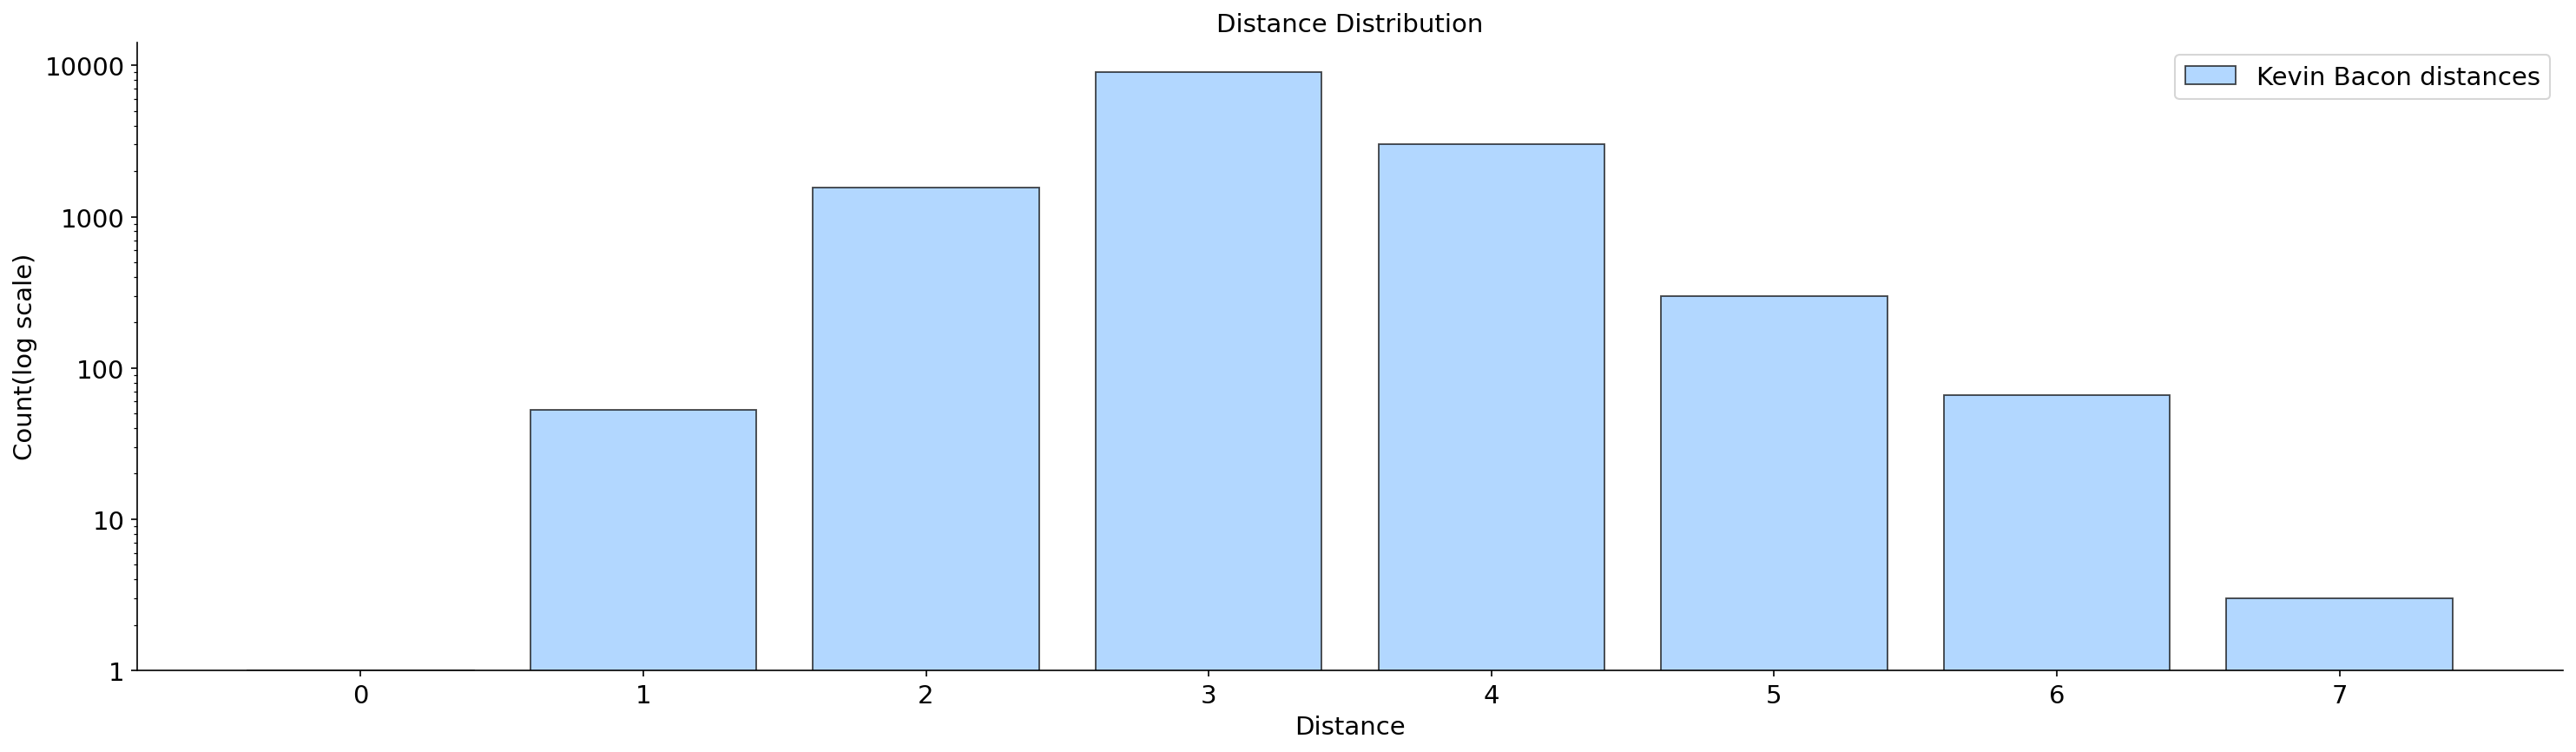

In [13]:
import importlib
from plotter import Plotter
importlib.reload(plotter)

sequence = df["distance"].to_numpy()
Plotter().plot_distance_distribution(
    sequence,
    label="Kevin Bacon distances",
    log_y_scale=True
)

In [15]:
print("Nodes with maximum distance")
df[df["distance"] == df["distance"].max()]

Nodes with maximum distance


,node,distance
14448,haren chatterjee,7.0
14449,haradhan banerjee,7.0
14873,kazuo hasegawa,7.0


Direct neigboors:  54


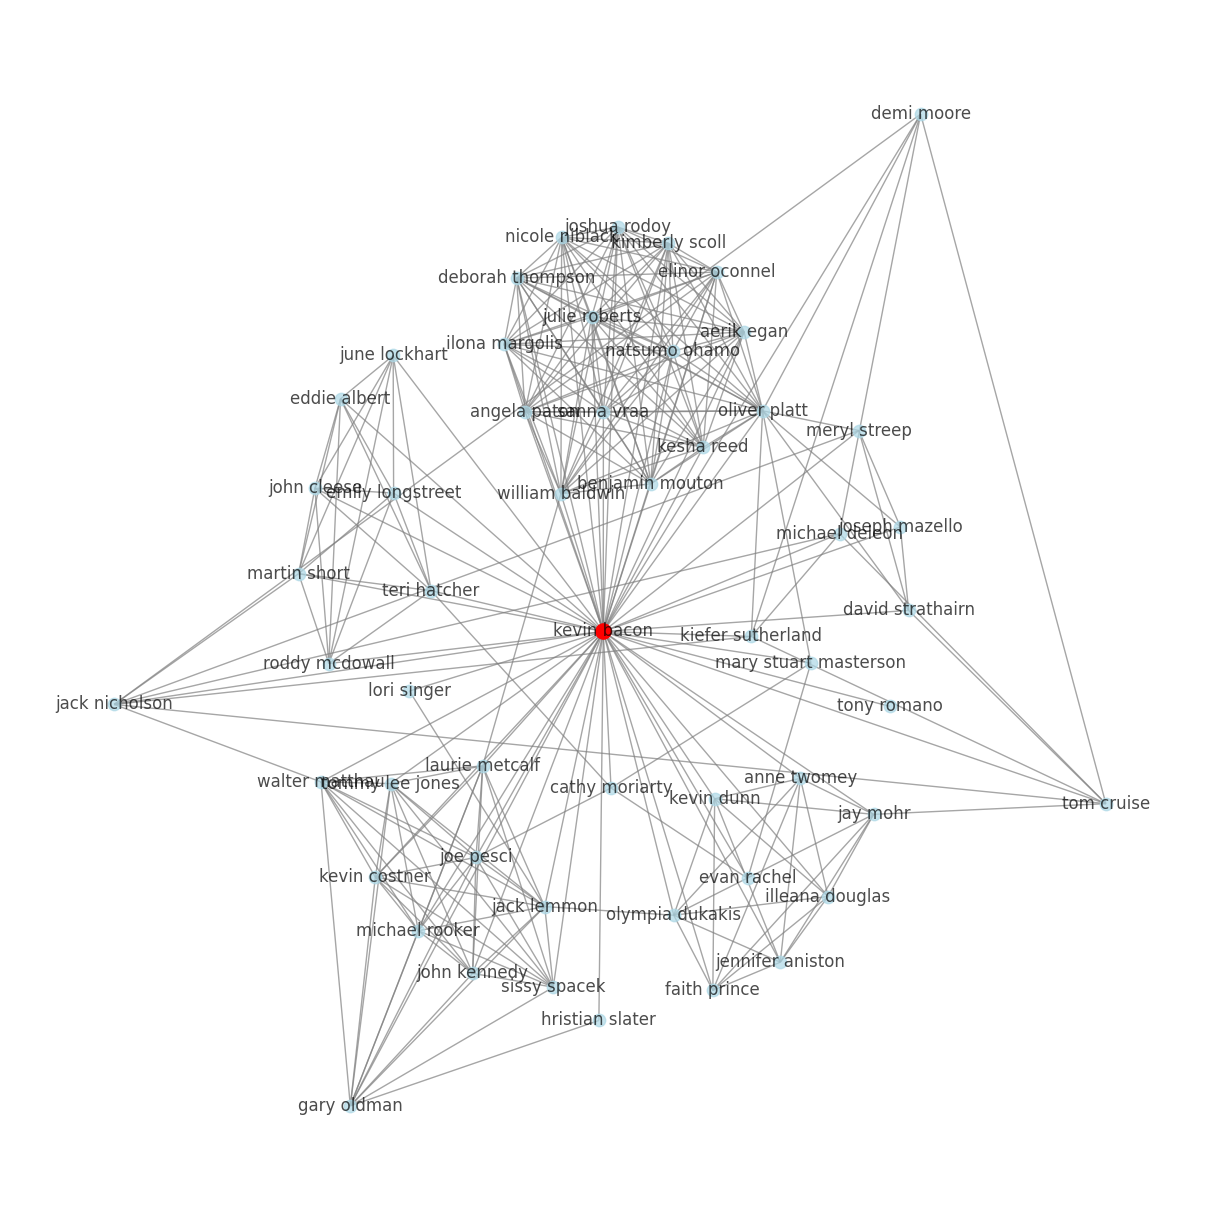

In [46]:
kevin_ego_g = nx.ego_graph(actors_graph.g, "kevin bacon", radius=1)
print("Direct neigboors: ", len(kevin_ego_g.nodes))
pos = nx.kamada_kawai_layout(kevin_ego_g)
scale = 1
pos = {k: (x * scale, y * scale) for k, (x, y) in pos.items()}
plt.figure(1, figsize=(12, 12))
nx.draw(
    kevin_ego_g,
    pos,
    node_size=80,
    node_color="lightblue",
    edge_color="gray",
    with_labels=True,
    alpha=0.7
)
nx.draw_networkx_nodes(
    kevin_ego_g,
    pos,
    nodelist=["kevin bacon"],
    node_color="red",
    node_size=120
)
plt.show()

In [8]:
actors_graph.g.nodes["kevin bacon"]

{'name': 'Kevin Bacon'}

## Graph embeddings

In [39]:
import networkx as nx
from node2vec import Node2Vec
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
train = False
# node2vec
if train:
    node2vec = Node2Vec(actors_graph.g, dimensions=50, walk_length=15, num_walks=200, workers=12)
    model = node2vec.fit(window=5, min_count=1, batch_words=4)
    model.save("../results/node2vec.model")
else:
    model = Word2Vec.load("../results/node2vec.model")

/home/taras-hamkalo/repositories/ddw/hamkatar/03/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [43]:
similar_to_kevin_bacon = model.wv.similar_by_key("kevin bacon", topn=53)
similar_to_kevin_bacon

[('tony romano', 0.9737507700920105),
 ('hristian slater', 0.881324291229248),
 ('aerik egan', 0.8667172193527222),
 ('benjamin mouton', 0.8656647205352783),
 ('angela paton', 0.8635957837104797),
 ('kimberly scoll', 0.8618102669715881),
 ('joshua rodoy', 0.8616056442260742),
 ('natsumo ohamo', 0.8610200881958008),
 ('kesha reed', 0.8606999516487122),
 ('ilona margolis', 0.8597076535224915),
 ('elinor oconnel', 0.8574268221855164),
 ('nicole niblack', 0.8568679094314575),
 ('deborah thompson', 0.8563035130500793),
 ('sanna vraa', 0.856009840965271),
 ('julie roberts', 0.8522075414657593),
 ('evan rachel', 0.8171087503433228),
 ('anne twomey', 0.8089148998260498),
 ('faith prince', 0.8001673221588135),
 ('michael deleon', 0.7725281119346619),
 ('emily longstreet', 0.7705467343330383),
 ('joseph mazello', 0.7573118805885315),
 ('jay mohr', 0.7393063306808472),
 ('jennifer aniston', 0.7292490005493164),
 ('cecily carroll', 0.6857315301895142),
 ('jan hook', 0.6826328039169312),
 ('william

In [104]:
similar_to_kevin_bacon_set = set([
  k for k, v in similar_to_kevin_bacon[:10]
])

kevin_ego_nodes_set = set(kevin_ego_g.nodes)
kevin_intersection = similar_to_kevin_bacon_set & kevin_ego_nodes_set
print("Intersection of top 53 similar and kevin direct neighbors length", len(kevin_intersection))
print(kevin_intersection)

Intersection of top 53 similar and kevin direct neighbors length 10
{'natsumo ohamo', 'tony romano', 'ilona margolis', 'aerik egan', 'hristian slater', 'kimberly scoll', 'angela paton', 'joshua rodoy', 'benjamin mouton', 'kesha reed'}


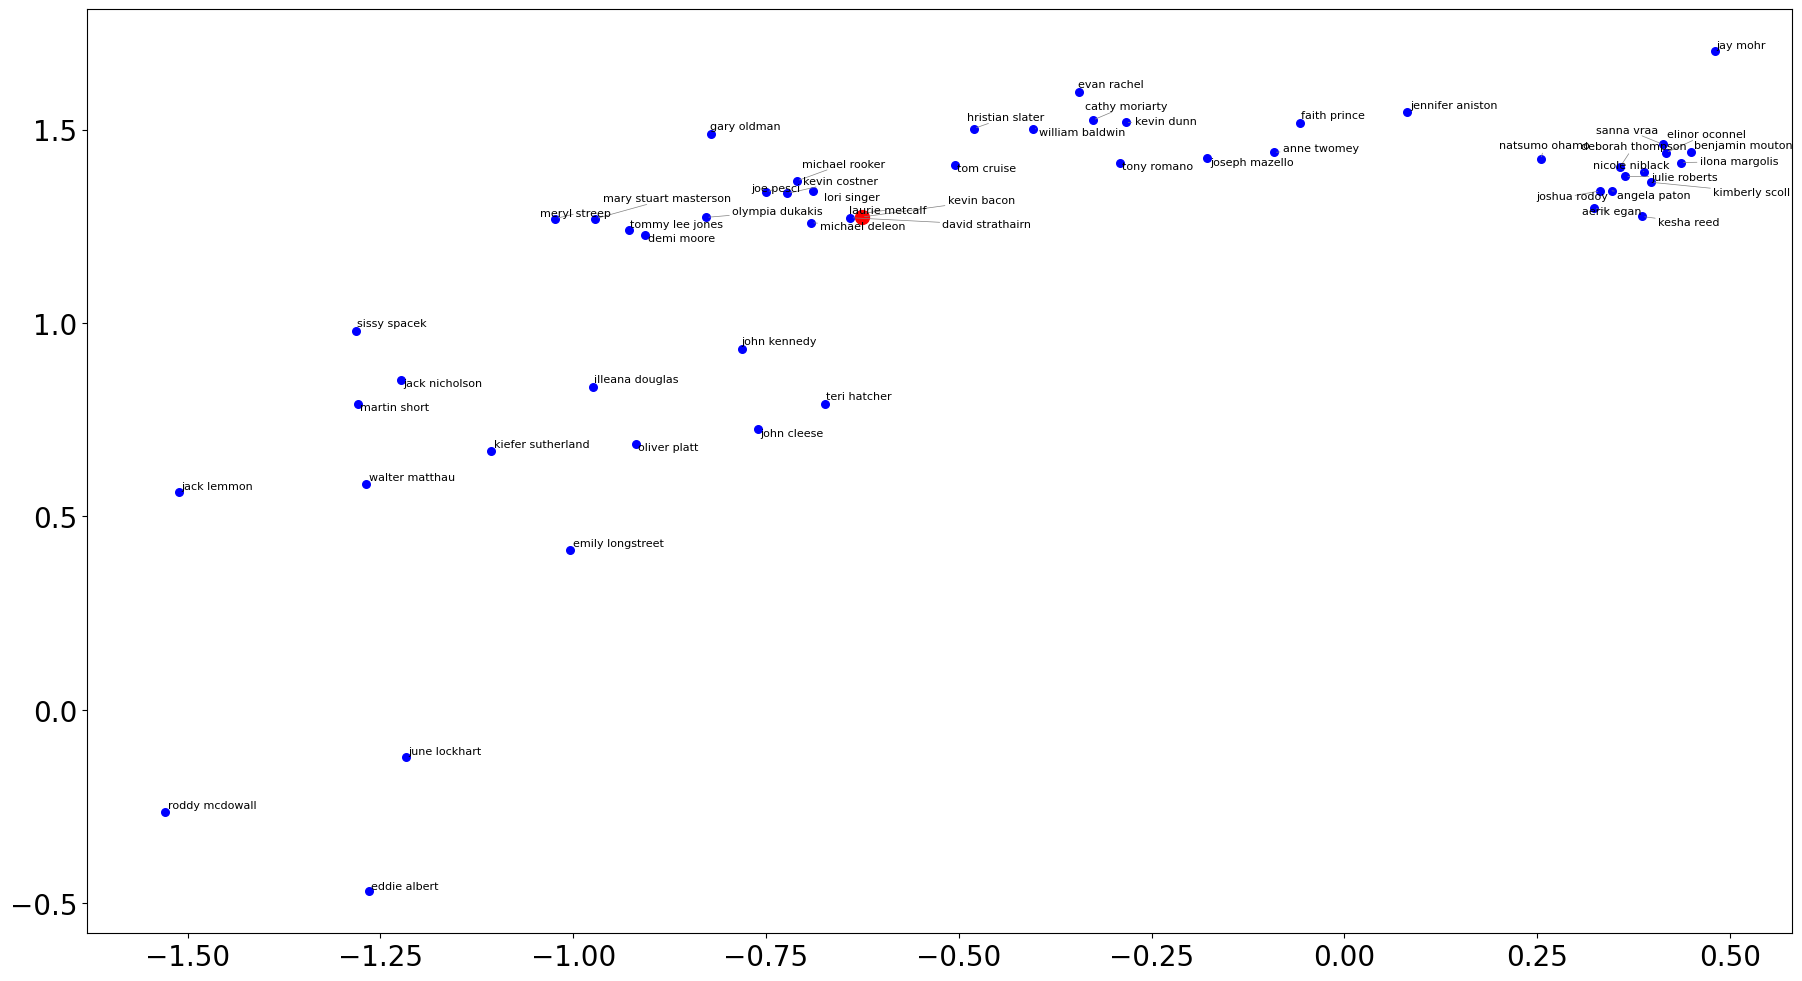

In [111]:
# visualize ego graph with radius 1
from adjustText import adjust_text

similar = [k for k in kevin_ego_nodes_set]
kevin_index = similar.index("kevin bacon")
vectors = [
    model.wv.get_vector(k) for k in similar
]

pca = PCA(n_components=2)
pca = pca.fit(model.wv.vectors)

pca_comps = pca.transform(vectors)

plt.figure(figsize=(22, 12))
plt.scatter(pca_comps[:, 0], pca_comps[:, 1], c='blue', s=30)
texts = []
for name, x, y in zip(similar, pca_comps[:, 0], pca_comps[:, 1]):
    texts.append(plt.text(x, y, name, fontsize=8))

plt.scatter(pca_comps[kevin_index, 0], pca_comps[kevin_index, 1], c='red', s=100)

adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

plt.show()

In [100]:
similar


['natsumo ohamo',
 'hristian slater',
 'william baldwin',
 'elinor oconnel',
 'teri hatcher',
 'kimberly scoll',
 'oliver platt',
 'evan rachel',
 'emily longstreet',
 'meryl streep',
 'kevin bacon',
 'joshua rodoy',
 'jay mohr',
 'laurie metcalf',
 'tom cruise',
 'nicole niblack',
 'demi moore',
 'gary oldman',
 'julie roberts',
 'jack nicholson',
 'deborah thompson',
 'ilona margolis',
 'kiefer sutherland',
 'lori singer',
 'angela paton',
 'michael rooker',
 'faith prince',
 'cathy moriarty',
 'june lockhart',
 'jennifer aniston',
 'illeana douglas',
 'tommy lee jones',
 'joe pesci',
 'roddy mcdowall',
 'joseph mazello',
 'sanna vraa',
 'walter matthau',
 'martin short',
 'jack lemmon',
 'tony romano',
 'benjamin mouton',
 'kesha reed',
 'david strathairn',
 'kevin dunn',
 'aerik egan',
 'eddie albert',
 'kevin costner',
 'anne twomey',
 'john kennedy',
 'sissy spacek',
 'john cleese',
 'mary stuart masterson',
 'olympia dukakis',
 'michael deleon',
 'kevin bacon']

In [102]:
similar.index("kevin bacon")

10